In [ ]:
# =====================================
# 1. Import Libraries
# =====================================
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Improve display formatting
pd.set_option('display.float_format', '{:.2f}'.format)

# =====================================
# 2. Load the Dataset
# =====================================
iris = load_iris()
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add species names
df['species'] = iris.target
df['species'] = df['species'].map({
    0: 'setosa',
    1: 'versicolor',
    2: 'virginica'
})
print("First 5 rows:")
print(df.head())

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0               5.10              3.50               1.40              0.20   
1               4.90              3.00               1.40              0.20   
2               4.70              3.20               1.30              0.20   
3               4.60              3.10               1.50              0.20   
4               5.00              3.60               1.40              0.20   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  



Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
None

Dataset Shape
(150, 5)

Missing Values
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


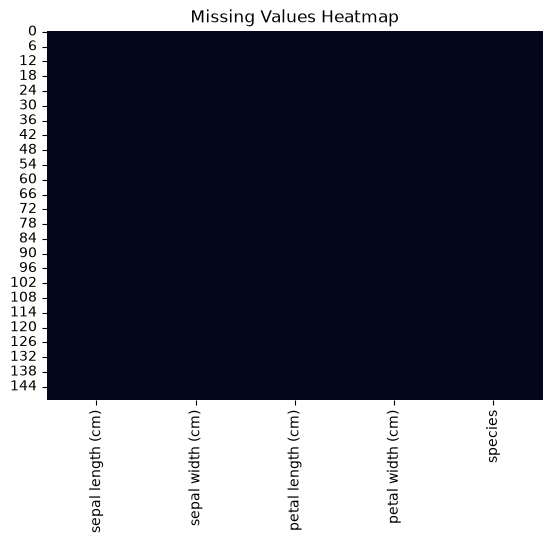


Descriptive Statistics
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count             150.00            150.00             150.00   
mean                5.84              3.06               3.76   
std                 0.83              0.44               1.77   
min                 4.30              2.00               1.00   
25%                 5.10              2.80               1.60   
50%                 5.80              3.00               4.35   
75%                 6.40              3.30               5.10   
max                 7.90              4.40               6.90   

       petal width (cm)  
count            150.00  
mean               1.20  
std                0.76  
min                0.10  
25%                0.30  
50%                1.30  
75%                1.80  
max                2.50  

Grouped by Species
            sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                           

In [ ]:
# =====================================
# 3. Inspect Dataset Structure
# =====================================
print("\nDataset Information")
print(df.info())
print("\nDataset Shape")
print(df.shape)

# =====================================
# 4. Check Missing Values
# =====================================
print("\nMissing Values")
print(df.isnull().sum())
# Visual check
sns.heatmap(df.isnull(), cbar=False)
plt.title('Missing Values Heatmap')
plt.show()

# =====================================
# 5. Descriptive Statistics
# =====================================
print("\nDescriptive Statistics")
print(df.describe())
print("\nGrouped by Species")
print(
df.groupby('species').mean().round(2)
)


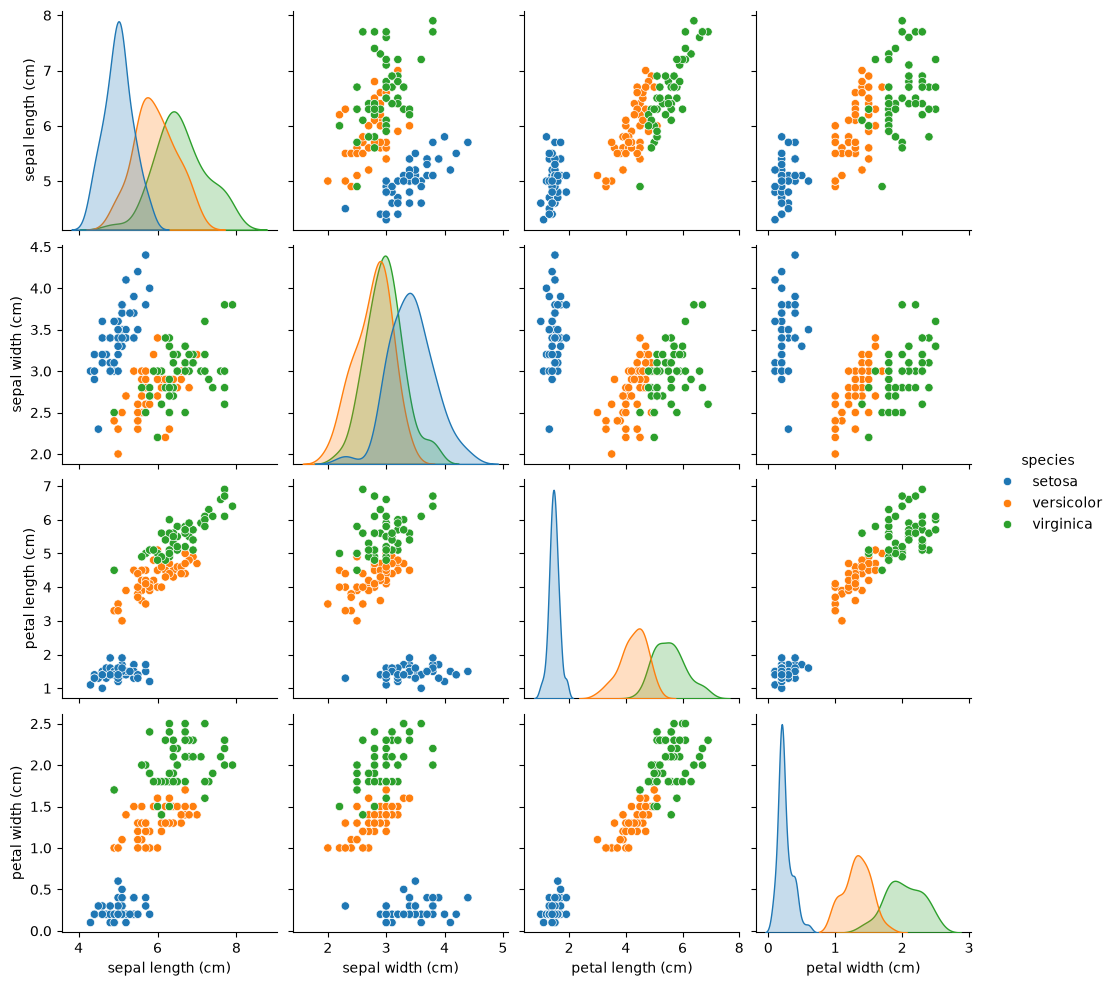

In [5]:
sns.pairplot(df, hue='species', height=2.5)

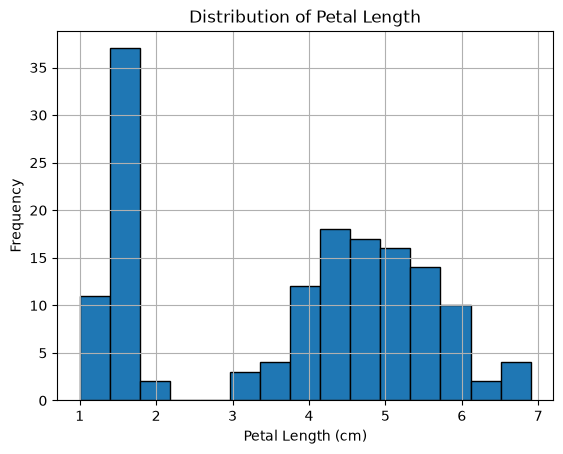

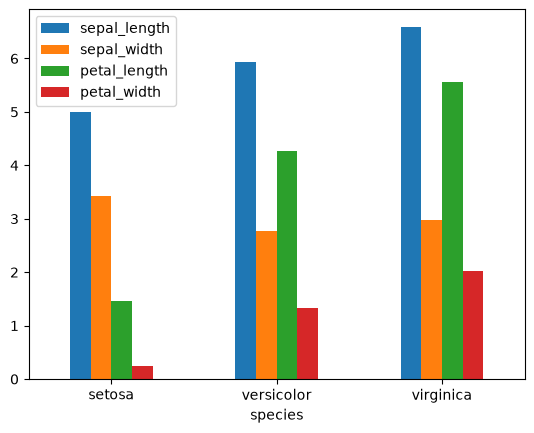

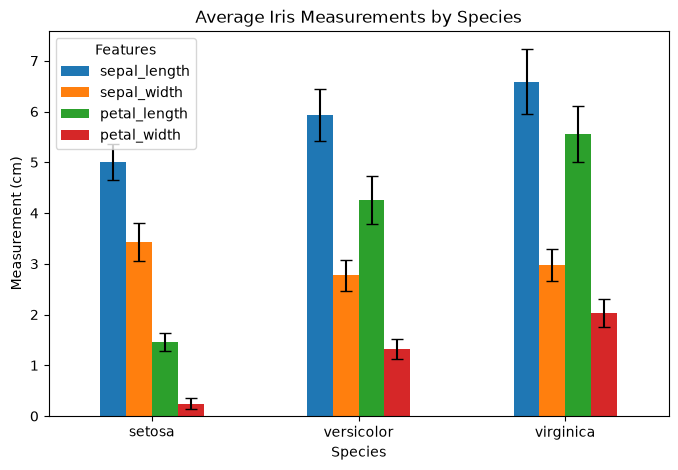

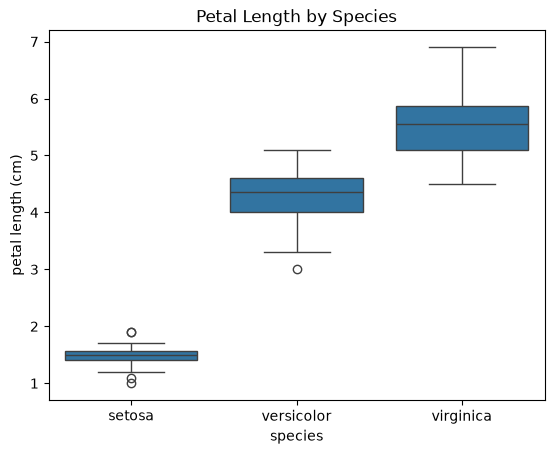

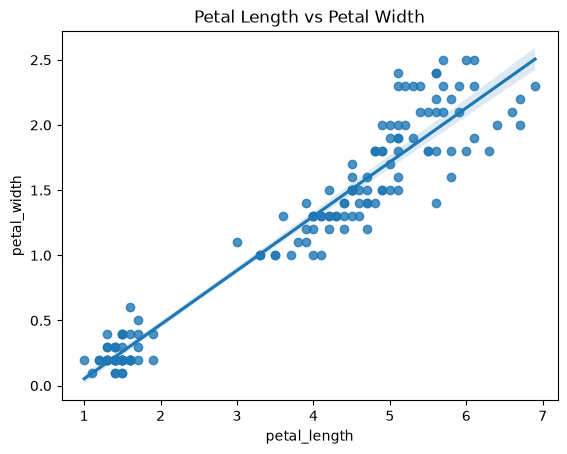

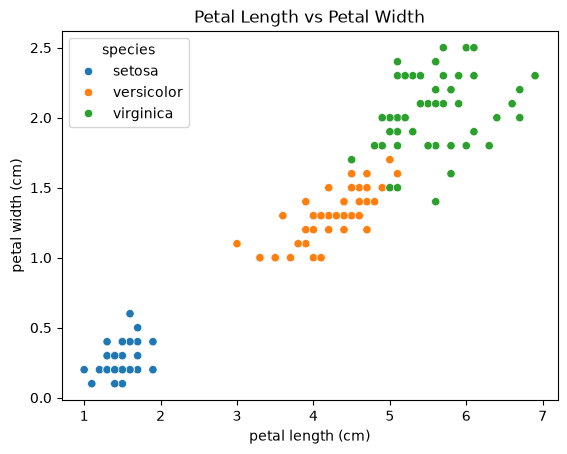

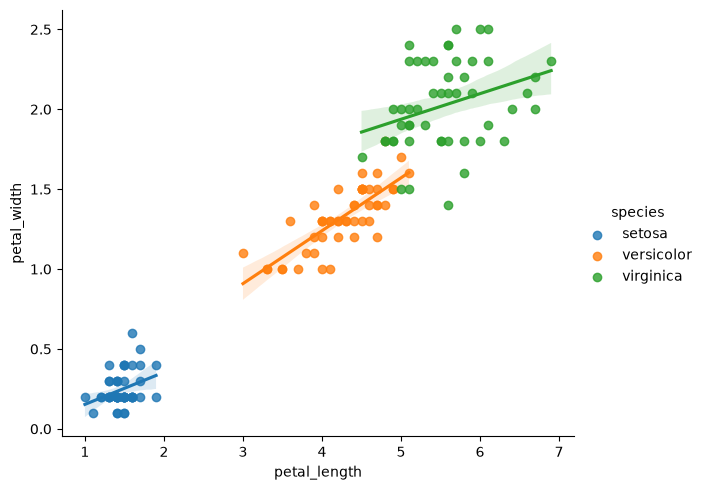

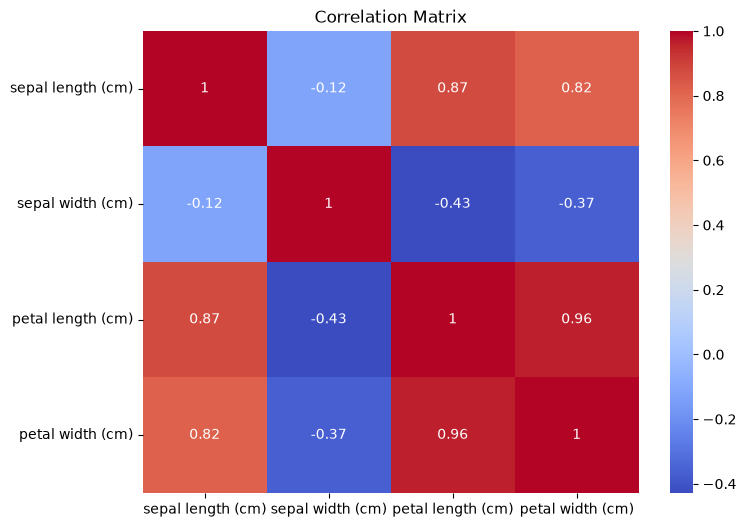

In [ ]:
# =====================================
# 6. Data Visualisations
# =====================================
# Histogram
df['petal length (cm)'].hist(
bins=15,
edgecolor='black'
)
plt.title('Distribution of Petal Length')
plt.xlabel('Petal Length (cm)')
plt.ylabel('Frequency')
plt.show()
#simple visualisation for the grouped plot
import seaborn as sns
import matplotlib.pyplot as plt
iris = sns.load_dataset("iris")
grouped = iris.groupby("species").mean()
grouped.plot(kind="bar")
plt.xticks(rotation=0)
plt.show()
#########################################################
#Grouped bar chart with error bars
## Mean values by species
grouped_mean = iris.groupby("species").mean()
# Standard deviations by species
grouped_std = iris.groupby("species").std()
# Grouped bar chart with error bars
grouped_mean.plot(
kind="bar",
yerr=grouped_std,
capsize=4,
figsize=(8, 5)
)
plt.title("Average Iris Measurements by Species")
plt.xlabel("Species")
plt.ylabel("Measurement (cm)")
plt.legend(title="Features")
plt.xticks(rotation=0)
plt.show()
################################################
# Boxplot
sns.boxplot(
x='species',
y='petal length (cm)',
data=df
)
plt.title('Petal Length by Species')
plt.show()

#scatter plot
import seaborn as sns
import matplotlib.pyplot as plt
iris = sns.load_dataset("iris")
sns.regplot(
data=iris,
x="petal_length",
y="petal_width"
)
plt.title("Petal Length vs Petal Width")
plt.show()

# Scatter Plot with colours to identify species
sns.scatterplot(
data=df,
x='petal length (cm)',
y='petal width (cm)',
hue='species'
)
plt.title('Petal Length vs Petal Width')
plt.show()

#Scatter plot with the line of best fit calculated per species
import seaborn as sns
import matplotlib.pyplot as plt
iris = sns.load_dataset("iris")
sns.lmplot(
data=iris,
x="petal_length",
y="petal_width",
hue="species",
height=5,
aspect=1.2
)
plt.show()

# Correlation Matrix
plt.figure(figsize=(8,6))
numeric_df = df.drop('species', axis=1)
sns.heatmap(
numeric_df.corr(),
annot=True,
cmap='coolwarm'
)
plt.title('Correlation Matrix')
plt.show()

In [7]:
# =====================================
# Regression Model
# Predict Petal Length
# =====================================
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
# Features
X = df[['sepal length (cm)',
'sepal width (cm)',
'petal width (cm)']]
# Target
y = df['petal length (cm)']
# Create model
model = LinearRegression()
# Train model on the full dataset
model.fit(X, y)
# Make predictions
y_pred = model.predict(X)
# Evaluate model
mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"R² Score: {r2:.2f}")

Mean Squared Error: 0.10
R² Score: 0.97


In [ ]:
import statsmodels.api as sm

# Features
X = df[['sepal length (cm)',
'sepal width (cm)',
'petal width (cm)']]
# Target
y = df['petal length (cm)']
# Add intercept
X = sm.add_constant(X)
# Fit regression model
model = sm.OLS(y, X).fit()
# Display full results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:      petal length (cm)   R-squared:                       0.968
Model:                            OLS   Adj. R-squared:                  0.967
Method:                 Least Squares   F-statistic:                     1473.
Date:                Tue, 03 Nov 2026   Prob (F-statistic):          6.98e-109
Time:                        15:35:12   Log-Likelihood:                -39.408
No. Observations:                 150   AIC:                             86.82
Df Residuals:                     146   BIC:                             98.86
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -0.2627      0.29

In [10]:
summary = pd.DataFrame({
'Coefficient': model.params,
'Std Error': model.bse,
't statistic': model.tvalues,
'p-value': model.pvalues
})
print(summary.round(4))

                   Coefficient  Std Error  t statistic  p-value
const                    -0.26       0.30        -0.88     0.38
sepal length (cm)         0.73       0.06        12.50     0.00
sepal width (cm)         -0.65       0.07        -9.43     0.00
petal width (cm)          1.45       0.07        21.40     0.00
